# 07 · Fairness, bias and robustness across subpopulations
Model analysed: the **reduced LightGBM** (18 features, notebook 06), at the screening rule *recall ≥ 80 % on validation* (one global threshold).

Attributes: **sex**, **age group** (18–44, 45–64, 65+) and **income group** (low: levels 1–4, i.e. under ~$25k; middle: 5–6; high: 7–8).

What "fair" means here: prevalence legitimately differs between groups (age!), so we do **not** ask for equal flag rates. We look at
- **equal opportunity:** do diabetic people in every group have the same chance of being detected (recall / TPR)?
- **false-alarm burden** (FPR) and **calibration** (does predicted risk match observed rate in each group?).

Then we ask whether the **explanations** differ between groups, and test a mitigation: **group-specific thresholds**.

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib, shap, warnings
from functools import partialmethod
from tqdm import tqdm; tqdm.__init__ = partialmethod(tqdm.__init__, disable=True)
from sklearn.metrics import roc_auc_score
import lightgbm as lgb
from src.preprocess import get_splits
from src.evaluation import threshold_for_recall
warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid")
X_tr, X_va, X_te, y_tr, y_va, y_te = get_splits()
red = joblib.load("../models/lightgbm_reduced.joblib")
keep = [c for c in X_tr.columns if c not in ["CholCheck", "HvyAlcoholConsump", "AnyHealthcare"]]
p_va, p_te = red.predict_proba(X_va[keep])[:, 1], red.predict_proba(X_te[keep])[:, 1]
thr = threshold_for_recall(y_va, p_va, 0.80); print(f"global threshold = {thr:.3f}")

def groups_of(X):
    return pd.DataFrame({
        "sex": np.where(X.Sex == 1, "male", "female"),
        "age": pd.cut(X.Age, [0, 5, 9, 13], labels=["18-44", "45-64", "65+"]).astype(str),
        "income": pd.cut(X.Income, [0, 4, 6, 8], labels=["low", "middle", "high"]).astype(str)}, index=X.index)
G_va, G_te = groups_of(X_va), groups_of(X_te)
print(G_te.apply(lambda c: c.value_counts().to_dict()).to_string())

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


global threshold = 0.147
sex                    {'female': 19235, 'male': 15187}
age       {'45-64': 14508, '65+': 12661, '18-44': 7253}
income     {'high': 16676, 'middle': 9071, 'low': 8675}


## 1. Performance and error rates by group (global threshold)
Recall (TPR) has a bootstrap 95 % CI (200 resamples) because some groups have few positives.

In [2]:
rng = np.random.default_rng(0)
def group_table(p, y, G, thr_by=None, n_boot=200):
    rows = []
    for attr in G.columns:
        for g in sorted(G[attr].unique()):
            m = (G[attr] == g).values; yy, pp = y.values[m], p[m]
            t = thr if thr_by is None else thr_by[(attr, g)]
            yhat = pp >= t; pos, neg = yy == 1, yy == 0
            boots = [yhat[i][yy[i] == 1].mean() for i in (rng.integers(0, m.sum(), m.sum()) for _ in range(n_boot))]
            rows.append({"attr": attr, "group": g, "n": int(m.sum()), "prevalence": yy.mean(), "ROC-AUC": roc_auc_score(yy, pp),
                         "recall": yhat[pos].mean(), "recall_lo": np.percentile(boots, 2.5), "recall_hi": np.percentile(boots, 97.5),
                         "FPR": yhat[neg].mean(), "precision": yy[yhat].mean() if yhat.any() else np.nan, "flagged": yhat.mean(),
                         "pred. risk": pp.mean(), "threshold": t})
    return pd.DataFrame(rows)
base = group_table(p_te, y_te, G_te); base.round(3)

,attr,group,n,prevalence,ROC-AUC,recall,recall_lo,recall_hi,FPR,precision,flagged,pred. risk,threshold
0,sex,female,19235,0.143,0.825,0.780,0.762,0.797,0.285,0.313,0.356,0.144,0.147
1,sex,male,15187,0.166,0.800,0.813,0.799,0.829,0.366,0.306,0.440,0.168,0.147
2,age,18-44,7253,0.048,0.854,0.423,0.365,0.469,0.057,0.272,0.074,0.046,0.147
3,age,45-64,14508,0.153,0.818,0.781,0.765,0.797,0.295,0.324,0.369,0.152,0.147
4,age,65+,12661,0.213,0.748,0.856,0.843,0.867,0.534,0.302,0.603,0.221,0.147
5,income,high,16676,0.108,0.822,0.695,0.678,0.715,0.223,0.275,0.275,0.112,0.147
6,income,low,8675,0.228,0.777,0.875,0.861,0.890,0.494,0.344,0.581,0.226,0.147
7,income,middle,9071,0.163,0.804,0.812,0.794,0.832,0.357,0.307,0.431,0.166,0.147


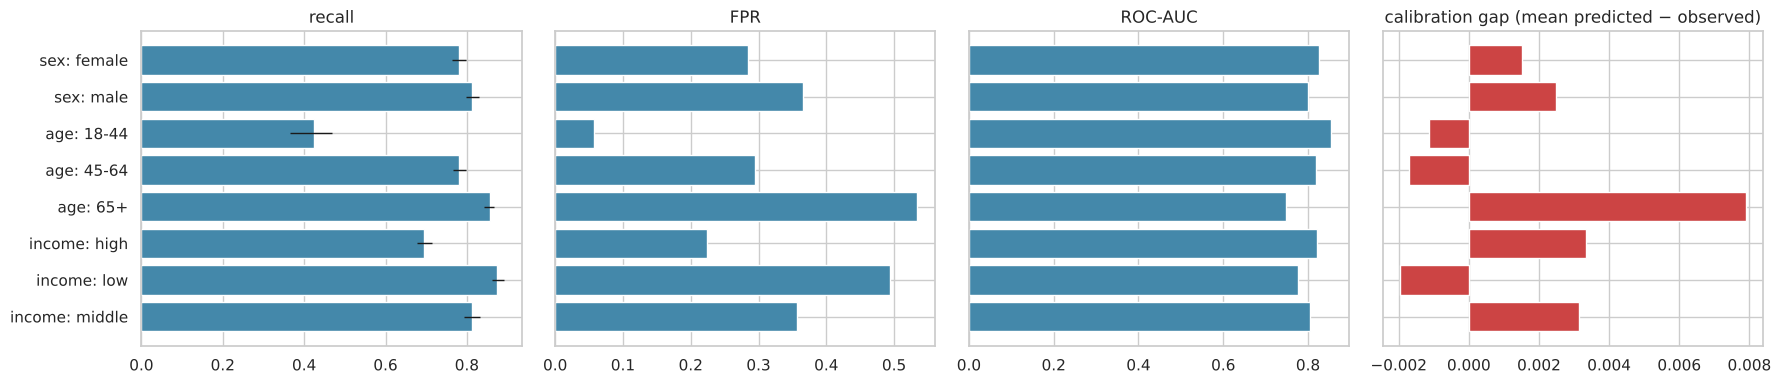

,recall_gap,FPR_gap,AUC_gap
attr,,,
age,0.432,0.478,0.107
income,0.180,0.270,0.046
sex,0.033,0.081,0.025


In [3]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
lab = base.attr + ": " + base.group
for ax, col in zip(axes[:3], ["recall", "FPR", "ROC-AUC"]):
    ax.barh(lab[::-1], base[col][::-1], color="#48a")
    if col == "recall": ax.errorbar(base.recall[::-1], range(len(base)), xerr=[(base.recall - base.recall_lo)[::-1], (base.recall_hi - base.recall)[::-1]], fmt="none", c="k", lw=1)
    ax.set_title(col)
    if col != "recall": ax.set_yticklabels([])
axes[3].barh(lab[::-1], (base["pred. risk"] - base.prevalence)[::-1], color="#c44"); axes[3].set_title("calibration gap (mean predicted − observed)"); axes[3].set_yticklabels([])
plt.tight_layout(); plt.savefig("../figures/fair_groups.png", dpi=150); plt.show()
gaps = base.groupby("attr").agg(recall_gap=("recall", lambda s: s.max() - s.min()), FPR_gap=("FPR", lambda s: s.max() - s.min()), AUC_gap=("ROC-AUC", lambda s: s.max() - s.min())).round(3); gaps

## 2. Do the explanations differ between groups?
SHAP (5,000-row test sample, 100-row background) for the reduced model. We compare mean |SHAP| of the top features per group, and the *signed* contribution of `Income` and `Sex` themselves.

In [4]:
rs = np.random.default_rng(0); idx = rs.choice(len(X_te), 5000, replace=False); Xs = X_te.iloc[idx]; Gs = G_te.iloc[idx]
bg = X_tr.sample(100, random_state=0)
sv = shap.TreeExplainer(red, data=bg[keep], feature_perturbation="interventional", model_output="raw")(Xs[keep]).values
S = pd.DataFrame(sv, columns=keep, index=Xs.index)
top = S.abs().mean().sort_values(ascending=False).index[:8]
rows = []
for attr in Gs.columns:
    for g in sorted(Gs[attr].unique()):
        m = (Gs[attr] == g).values; rows.append(pd.Series(S[m].abs().mean()[top], name=f"{attr}: {g}"))
imp = pd.DataFrame(rows); imp.round(3)

 24%|=====               | 1203/5000 [00:11<00:34]       

 26%|=====               | 1316/5000 [00:12<00:33]       

 29%|======              | 1432/5000 [00:13<00:32]       

 31%|======              | 1546/5000 [00:14<00:31]       

 33%|=======             | 1660/5000 [00:15<00:30]       

...

 93%|=================== | 4651/5000 [00:41<00:03]       

 95%|=================== | 4764/5000 [00:42<00:02]       

 98%|===================| 4878/5000 [00:43<00:01]       

100%|===================| 4991/5000 [00:44<00:00]       

,GenHlth,Age,BMI,HighBP,HighChol,Sex,Income,MentHlth
sex: female,0.540,0.373,0.428,0.363,0.287,0.089,0.112,0.097
sex: male,0.492,0.454,0.335,0.339,0.261,0.149,0.083,0.091
age: 18-44,0.556,0.894,0.373,0.360,0.318,0.072,0.102,0.126
age: 45-64,0.555,0.168,0.390,0.368,0.288,0.110,0.100,0.100
age: 65+,0.454,0.400,0.392,0.330,0.235,0.148,0.098,0.068
income: high,0.534,0.422,0.377,0.358,0.270,0.132,0.095,0.103
income: low,0.512,0.387,0.413,0.348,0.287,0.085,0.180,0.087
income: middle,0.497,0.405,0.382,0.346,0.274,0.115,0.033,0.085


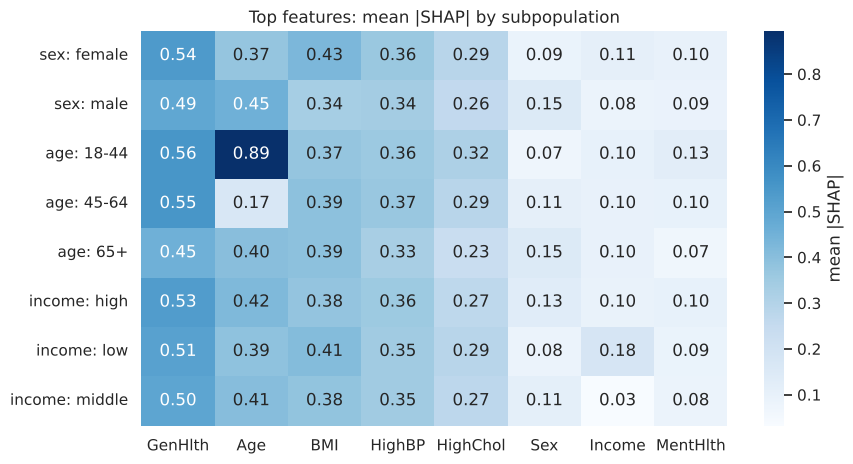

,mean SHAP of Income,mean SHAP of Sex
sex: female,0.016,-0.089
sex: male,-0.015,0.149
age: 18-44,-0.014,0.014
age: 45-64,-0.014,0.015
age: 65+,0.031,0.018
income: high,-0.095,0.027
income: low,0.180,-0.004
income: middle,0.014,0.015


In [5]:
fig, ax = plt.subplots(figsize=(9, 4.8)); sns.heatmap(imp, annot=True, fmt=".2f", cmap="Blues", ax=ax, cbar_kws={"label": "mean |SHAP|"})
ax.set_title("Top features: mean |SHAP| by subpopulation"); plt.tight_layout(); plt.savefig("../figures/fair_shap_groups.png", dpi=150); plt.show()
sign = pd.DataFrame({f"{a}: {g}": {"mean SHAP of Income": S.loc[(Gs[a] == g).values, "Income"].mean(), "mean SHAP of Sex": S.loc[(Gs[a] == g).values, "Sex"].mean()}
                     for a in Gs.columns for g in sorted(Gs[a].unique())}).T.round(3); sign

## 3. Mitigation: group-specific thresholds (equal opportunity)
For each attribute separately, choose per-group thresholds on **validation** so that recall ≈ 80 % inside every group, and evaluate on test.
(Using a protected attribute at decision time can be legally problematic; we use it here to measure the cost of equalising recall.)

In [6]:
thr_by = {}
for attr in G_va.columns:
    for g in sorted(G_va[attr].unique()):
        m = (G_va[attr] == g).values; thr_by[(attr, g)] = threshold_for_recall(y_va.values[m], p_va[m], 0.80)
mit = group_table(p_te, y_te, G_te, thr_by=thr_by)
cmp = base[["attr", "group", "recall", "FPR", "precision", "flagged"]].merge(mit[["attr", "group", "threshold", "recall", "FPR", "precision", "flagged"]], on=["attr", "group"], suffixes=("_global", "_group-thr"))
cmp.round(3)

,attr,group,recall_global,FPR_global,precision_global,flagged_global,threshold,recall_group-thr,FPR_group-thr,precision_group-thr,flagged_group-thr
0,sex,female,0.780,0.285,0.313,0.356,0.143,0.789,0.293,0.310,0.364
1,sex,male,0.813,0.366,0.306,0.440,0.149,0.809,0.361,0.308,0.435
2,age,18-44,0.423,0.057,0.272,0.074,0.033,0.864,0.308,0.123,0.334
3,age,45-64,0.781,0.295,0.324,0.369,0.132,0.809,0.329,0.308,0.403
4,age,65+,0.856,0.534,0.302,0.603,0.177,0.798,0.447,0.325,0.522
5,income,high,0.695,0.223,0.275,0.275,0.100,0.829,0.328,0.235,0.383
6,income,low,0.875,0.494,0.344,0.581,0.202,0.788,0.382,0.379,0.475
7,income,middle,0.812,0.357,0.307,0.431,0.154,0.800,0.341,0.314,0.415


In [7]:
summ = []
for attr in G_te.columns:
    for name, tab in [("global threshold", base), ("group thresholds", mit)]:
        t = tab[tab.attr == attr]
        m_all = np.zeros(len(y_te), bool); yhat = np.zeros(len(y_te), bool)
        for g in t.group:
            m = (G_te[attr] == g).values; yhat[m] = p_te[m] >= (thr if name == "global threshold" else thr_by[(attr, g)])
        summ.append({"attribute": attr, "rule": name, "recall gap": t.recall.max() - t.recall.min(), "FPR gap": t.FPR.max() - t.FPR.min(),
                     "overall recall": yhat[y_te.values == 1].mean(), "overall precision": y_te.values[yhat].mean(), "overall flagged": yhat.mean()})
summ = pd.DataFrame(summ).round(3); summ

,attribute,rule,recall gap,FPR gap,overall recall,overall precision,overall flagged
0,sex,global threshold,0.033,0.081,0.796,0.310,0.393
1,sex,group thresholds,0.019,0.068,0.799,0.309,0.396
2,age,global threshold,0.432,0.478,0.796,0.310,0.393
3,age,group thresholds,0.066,0.140,0.807,0.286,0.432
4,income,global threshold,0.180,0.270,0.796,0.310,0.393
5,income,group thresholds,0.041,0.054,0.805,0.297,0.415


## 4. Does "fairness through unawareness" work?
Retrain without `Sex` and `Income` (the two sensitive features the model can use directly; `Age` is medically relevant and kept) and see whether the gaps shrink.

In [8]:
keep2 = [c for c in keep if c not in ("Sex", "Income")]
m2 = lgb.LGBMClassifier(**{**red.get_params(), "n_estimators": 3000}).fit(X_tr[keep2], y_tr, eval_set=[(X_va[keep2], y_va)], eval_metric="binary_logloss", callbacks=[lgb.early_stopping(100, verbose=False)])
p2_va, p2_te = m2.predict_proba(X_va[keep2])[:, 1], m2.predict_proba(X_te[keep2])[:, 1]
thr2 = threshold_for_recall(y_va, p2_va, 0.80)
unaware = group_table(p2_te, y_te, G_te, thr_by={k: thr2 for k in thr_by})
print("overall ROC-AUC: with Sex+Income", round(roc_auc_score(y_te, p_te), 3), "| without", round(roc_auc_score(y_te, p2_te), 3))
out = pd.DataFrame({"recall_with": base.set_index(["attr", "group"]).recall, "recall_without": unaware.set_index(["attr", "group"]).recall}).round(3); out

overall ROC-AUC: with Sex+Income 0.815 | without 0.812


recall_with  recall_without
attr   group                              
sex    female        0.780           0.812
       male          0.813           0.797
age    18-44         0.423           0.435
       45-64         0.781           0.788
       65+           0.856           0.866
income high          0.695           0.726
       low           0.875           0.866
       middle        0.812           0.819

In [9]:
g1 = base.groupby("attr").recall.agg(lambda s: s.max() - s.min()); g2 = unaware.groupby("attr").recall.agg(lambda s: s.max() - s.min())
pd.DataFrame({"recall gap (with Sex, Income)": g1, "recall gap (without)": g2}).round(3)

,"recall gap (with Sex, Income)",recall gap (without)
attr,,
age,0.432,0.431
income,0.180,0.140
sex,0.033,0.015


## 5. Conclusions
- **Age is the big gap:** at one global threshold recall is 42 % for 18–44 (≈350 diabetic people in test), 78 % for 45–64 and 86 % for 65+ (gap 0.43). Age dominates the score, so young diabetic people get low risk (mean |SHAP| of Age = 0.89 in this group vs 0.17 in 45–64) and are missed.
- **Income:** recall is 87 % in the low-income group vs 70 % in the high-income group (gap 0.18), but low-income people also carry the heaviest false-alarm burden (FPR 49 % vs 22 %; 58 % flagged vs 28 %). The model uses `Income` directly as a risk factor (mean SHAP +0.18 for low income, −0.10 for high).
- **Sex:** small gap (recall 78 % female vs 81 % male).
- **Calibration is good in every group** (predicted vs observed rate within ~1 point, e.g. 0.226 vs 0.228 for low income). With different prevalence across groups, a calibrated score cannot also give equal TPR and FPR everywhere; this is a known trade-off, so the differences above are largely base-rate driven rather than a sign of a broken model.
- **Mitigation works but has a price:** group-specific thresholds bring the recall gap to 0.07 (age), 0.04 (income) and 0.02 (sex), at the cost of more false alarms (overall precision 0.310 → 0.286 for age; for 18–44 the threshold drops to 0.033, flagging a third of young people with 12 % precision). Using group-specific rules requires using the protected attribute at decision time, which may not be legally or ethically acceptable.
- **Unawareness is not enough:** dropping `Sex` and `Income` costs 0.003 AUC and narrows the income gap only from 0.18 to 0.14 (proxies such as education and health status remain); the age gap does not change (Age is kept because it is medically relevant).
- **Caveats:** one test split, groups with few positives (young people), coarse groups, and the label is diagnosed diabetes, which is itself unequally recorded across groups.